
#### **Name: Muniba Manaal**
#### **Class: BAI-5A**


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from keras import models, layers
from keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
from sklearn import tree
import matplotlib.pyplot as plt

In [ ]:
data = pd.read_csv('/content/IoTID20.csv')

In [ ]:
df = pd.DataFrame(data)
df.head()


,Flow_ID,Src_IP,Src_Port,Dst_IP,Dst_Port,Protocol,Timestamp,Flow_Duration,Tot_Fwd_Pkts,Tot_Bwd_Pkts,...,Active_Std,Active_Max,Active_Min,Idle_Mean,Idle_Std,Idle_Max,Idle_Min,Label,Cat,Sub_Cat
0,192.168.0.13-192.168.0.16-10000-10101-17,192.168.0.13,10000,192.168.0.16,10101,17,25/07/2019 03:25:53 AM,75,1,1,...,0.0,0.0,0.0,75.0,0.000000,75.0,75.0,Anomaly,Mirai,Mirai-Ackflooding
1,192.168.0.13-222.160.179.132-554-2179-6,222.160.179.132,2179,192.168.0.13,554,6,26/05/2019 10:11:06 PM,5310,1,2,...,0.0,0.0,0.0,2655.0,2261.327486,4254.0,1056.0,Anomaly,DoS,DoS-Synflooding
2,192.168.0.13-192.168.0.16-9020-52727-6,192.168.0.16,52727,192.168.0.13,9020,6,11/07/2019 01:24:48 AM,141,0,3,...,0.0,0.0,0.0,70.5,0.707107,71.0,70.0,Anomaly,Scan,Scan Port OS
3,192.168.0.13-192.168.0.16-9020-52964-6,192.168.0.16,52964,192.168.0.13,9020,6,04/09/2019 03:58:17 AM,151,0,2,...,0.0,0.0,0.0,151.0,0.000000,151.0,151.0,Anomaly,Mirai,Mirai-Hostbruteforceg
4,192.168.0.1-239.255.255.250-36763-1900-17,192.168.0.1,36763,239.255.255.250,1900,17,10/09/2019 01:41:18 AM,153,2,1,...,0.0,0.0,0.0,76.5,0.707107,77.0,76.0,Anomaly,Mirai,Mirai-Hostbruteforceg


In [ ]:
df.replace([np.inf, -np.inf], np.nan, inplace=True)

In [ ]:
df.dropna(inplace=True)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 625783 entries, 0 to 625782
Data columns (total 86 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Flow_ID            625783 non-null  object 
 1   Src_IP             625783 non-null  object 
 2   Src_Port           625783 non-null  int64  
 3   Dst_IP             625783 non-null  object 
 4   Dst_Port           625783 non-null  int64  
 5   Protocol           625783 non-null  int64  
 6   Timestamp          625783 non-null  object 
 7   Flow_Duration      625783 non-null  int64  
 8   Tot_Fwd_Pkts       625783 non-null  int64  
 9   Tot_Bwd_Pkts       625783 non-null  int64  
 10  TotLen_Fwd_Pkts    625783 non-null  float64
 11  TotLen_Bwd_Pkts    625783 non-null  float64
 12  Fwd_Pkt_Len_Max    625783 non-null  float64
 13  Fwd_Pkt_Len_Min    625783 non-null  float64
 14  Fwd_Pkt_Len_Mean   625783 non-null  float64
 15  Fwd_Pkt_Len_Std    625783 non-null  float64
 16  Bw

In [ ]:
df.isnull().sum()

,0
Flow_ID,0
Src_IP,0
Src_Port,0
Dst_IP,0
Dst_Port,0
...,...
Idle_Max,0
Idle_Min,0
Label,0
Cat,0


In [ ]:
df.isnull().values.any()

False

In [ ]:

label_encoder_binary = LabelEncoder()
label_encoder_multi = LabelEncoder()

# Assuming the third last column is binary and the second last is multiclass
binary_labels = label_encoder_binary.fit_transform(df.iloc[:, -3].values)
multiclass_labels = label_encoder_multi.fit_transform(df.iloc[:, -2].values)

# Prepare feature set X by excluding last three columns (leaving only numeric and necessary features)
X = df.iloc[:, :-3].copy()

# Apply Label Encoding to any remaining categorical columns in X
for column in X.select_dtypes(include=['object']).columns:
    X[column] = LabelEncoder().fit_transform(X[column])

In [ ]:
# Outlier Removal using IQR
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1
X = X[~((X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))).any(axis=1)]

In [ ]:
# Check that we still have corresponding labels after outlier removal
binary_labels = binary_labels[:len(X)]
multiclass_labels = multiclass_labels[:len(X)]

In [ ]:
# Split data for binary classification
X_train_binary, X_test_binary, y_train_binary, y_test_binary = train_test_split(
    X, binary_labels, test_size=0.2, random_state=42
)

# Split data for multiclass classification
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X, multiclass_labels, test_size=0.2, random_state=42
)


In [ ]:
# Decision Tree for Binary Classification
dt_classifier = DecisionTreeClassifier()

In [ ]:
dt_classifier.fit(X_train_binary, y_train_binary)
y_pred_binary_dt = dt_classifier.predict(X_test_binary)

In [ ]:
print("Decision Tree - Binary Classification")
print("Accuracy:", accuracy_score(y_test_binary, y_pred_binary_dt))

Decision Tree - Binary Classification
Accuracy: 0.8973061843935753


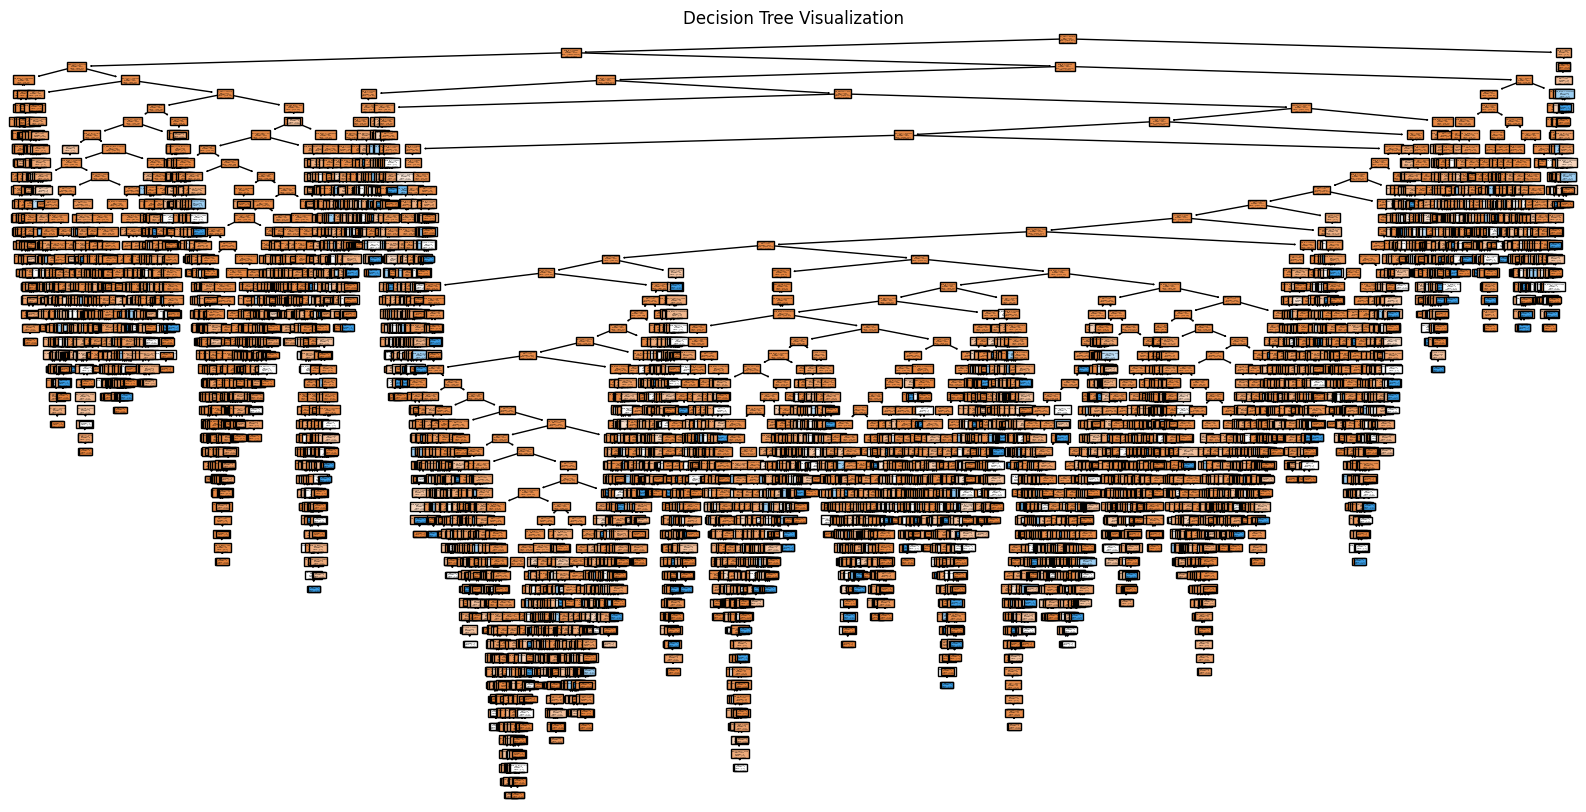

In [ ]:
# Tree Visualization
plt.figure(figsize=(20, 10))
tree.plot_tree(dt_classifier, filled=True, feature_names=X.columns, class_names=label_encoder_binary.classes_)
plt.title("Decision Tree Visualization")
plt.show()

In [ ]:
print("Classification Report:\n", classification_report(y_test_binary, y_pred_binary_dt))

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.96      0.95      7401
           1       0.06      0.04      0.05       506

    accuracy                           0.90      7907
   macro avg       0.50      0.50      0.50      7907
weighted avg       0.88      0.90      0.89      7907



In [ ]:
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay


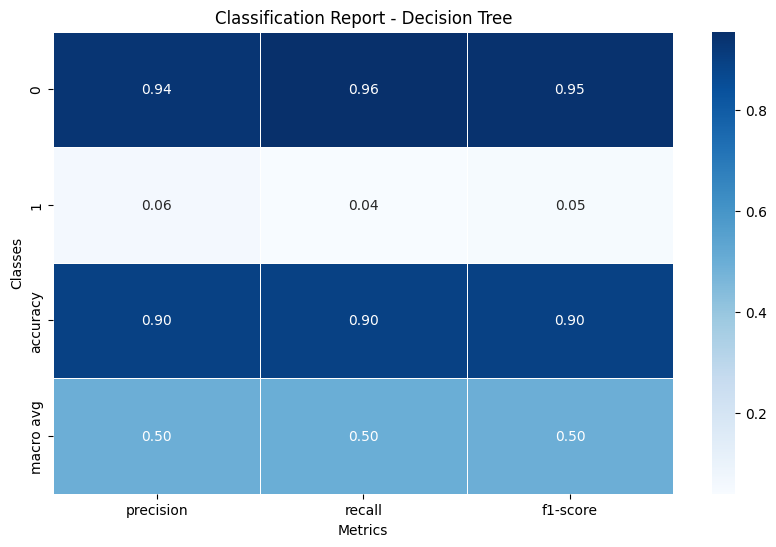

In [ ]:
# Plotting Classification Report
report = classification_report(y_test_binary, y_pred_binary_dt, output_dict=True)

# Convert to DataFrame for seaborn plotting
report_df = pd.DataFrame(report).transpose()

# Plotting the classification report as a heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(report_df.iloc[:-1, :-1], annot=True, cmap='Blues', fmt='.2f', linewidths=0.5)
plt.title('Classification Report - Decision Tree')
plt.xlabel('Metrics')
plt.ylabel('Classes')
plt.show()

In [ ]:
print("Confusion Matrix:\n", confusion_matrix(y_test_binary, y_pred_binary_dt))

Confusion Matrix:
 [[7075  326]
 [ 486   20]]


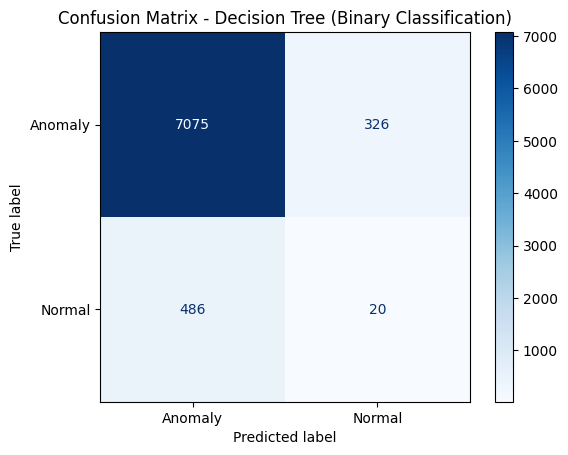

In [ ]:

cm = confusion_matrix(y_test_binary, y_pred_binary_dt)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder_binary.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - Decision Tree (Binary Classification)")
plt.show()

In [ ]:
# Naive Bayes for Binary Classification
nb_classifier = GaussianNB()
nb_classifier.fit(X_train_binary, y_train_binary)
y_pred_binary_nb = nb_classifier.predict(X_test_binary)

In [ ]:
print("Naive Bayes - Binary Classification")
print("Accuracy:", accuracy_score(y_test_binary, y_pred_binary_nb))


Naive Bayes - Binary Classification
Accuracy: 0.9360060705703807


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


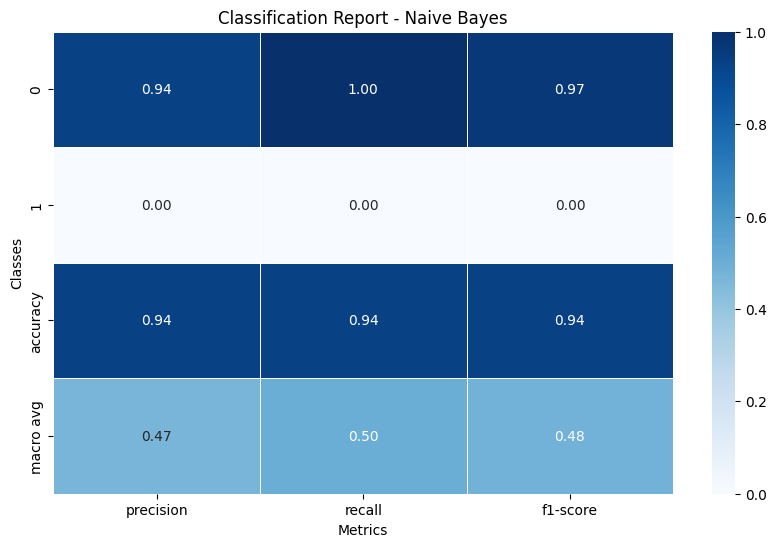

In [ ]:
# Plotting Classification Report for Naive Bayes
report_nb = classification_report(y_test_binary, y_pred_binary_nb, output_dict=True)
report_nb_df = pd.DataFrame(report_nb).transpose()
plt.figure(figsize=(10, 6))
sns.heatmap(report_nb_df.iloc[:-1, :-1], annot=True, cmap='Blues', fmt='.2f', linewidths=0.5)
plt.title('Classification Report - Naive Bayes')
plt.xlabel('Metrics')
plt.ylabel('Classes')
plt.show()


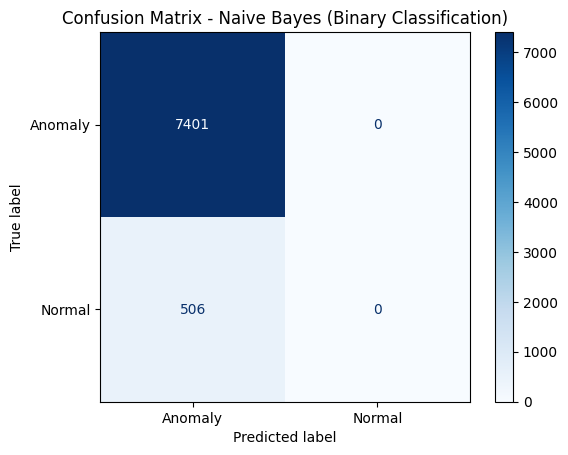

In [ ]:
# Confusion Matrix for Naive Bayes
cm_nb = confusion_matrix(y_test_binary, y_pred_binary_nb)
disp_nb = ConfusionMatrixDisplay(confusion_matrix=cm_nb, display_labels=label_encoder_binary.classes_)
disp_nb.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - Naive Bayes (Binary Classification)")
plt.show()

In [ ]:
print("Confusion Matrix (Naive Bayes):\n", confusion_matrix(y_test_binary, y_pred_binary_nb))

Confusion Matrix (Naive Bayes):
 [[7401    0]
 [ 506    0]]


In [ ]:
# Define the Neural Network Model
model = models.Sequential()
model.add(layers.Dense(64, activation='relu', input_shape=(X_train_binary.shape[1],)))
model.add(layers.Dense(32, activation='relu'))
model.add(layers.Dense(1, activation='sigmoid'))  # Output layer for binary classification

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
history = model.fit(X_train_binary, y_train_binary, epochs=13, batch_size=32, validation_split=0.2)


Epoch 1/13
791/791 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.8731 - loss: 9945.2725 - val_accuracy: 0.9364 - val_loss: 5597.1597
Epoch 2/13
791/791 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8766 - loss: 5583.2739 - val_accuracy: 0.9357 - val_loss: 3191.3423
Epoch 3/13
791/791 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8824 - loss: 3898.1553 - val_accuracy: 0.9364 - val_loss: 2989.9751
Epoch 4/13
791/791 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8803 - loss: 3302.8308 - val_accuracy: 0.9292 - val_loss: 1942.9595
Epoch 5/13
791/791 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8745 - loss: 3269.5217 - val_accuracy: 0.9364 - val_loss: 6013.0342
Epoch 6/13
791/791 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8756 - loss: 2570.0767 - val_accuracy: 0.9357 - val_loss: 1676.0835
Epoch 7/13
791/791 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8756 - loss: 2142.7800 - val_accuracy: 0.9331 - val_loss: 1224.4508
Epoch 8/13
791/791 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy

In [ ]:
# Evaluate the model
loss, accuracy = model.evaluate(X_test_binary, y_test_binary)
print("Neural Network - Binary Classification")
print("Test Accuracy:", accuracy)

248/248 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9324 - loss: 659.7354
Neural Network - Binary Classification
Test Accuracy: 0.9356266856193542


In [ ]:

# Predictions
y_pred_binary_nn = (model.predict(X_test_binary) > 0.5).astype("int32")


248/248 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [ ]:

# Evaluation Metrics
print("Classification Report:\n", classification_report(y_test_binary, y_pred_binary_nn))


Classification Report:
               precision    recall  f1-score   support

           0       0.94      1.00      0.97      7401
           1       0.00      0.00      0.00       506

    accuracy                           0.94      7907
   macro avg       0.47      0.50      0.48      7907
weighted avg       0.88      0.94      0.90      7907



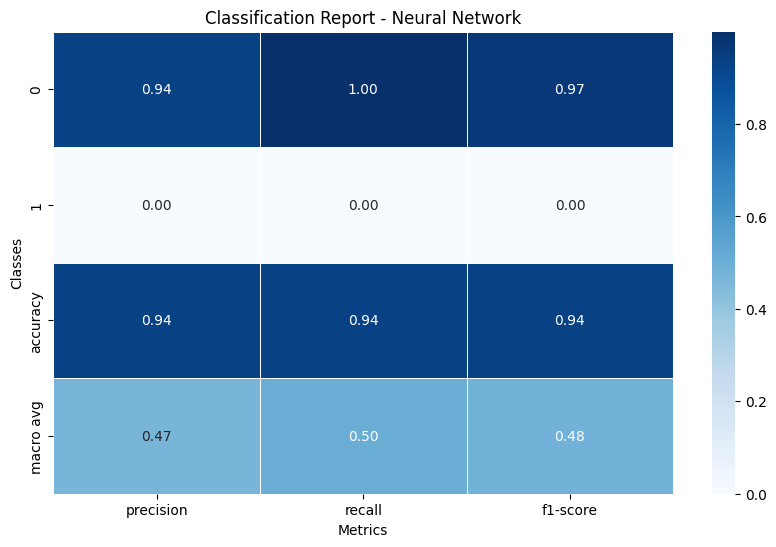

In [ ]:
# Plotting Classification Report for Neural Network
report_nn = classification_report(y_test_binary, y_pred_binary_nn, output_dict=True)
report_nn_df = pd.DataFrame(report_nn).transpose()
plt.figure(figsize=(10, 6))
sns.heatmap(report_nn_df.iloc[:-1, :-1], annot=True, cmap='Blues', fmt='.2f', linewidths=0.5)
plt.title('Classification Report - Neural Network')
plt.xlabel('Metrics')
plt.ylabel('Classes')
plt.show()

In [ ]:
print("Confusion Matrix:\n", confusion_matrix(y_test_binary, y_pred_binary_nn))


Confusion Matrix:
 [[7398    3]
 [ 506    0]]


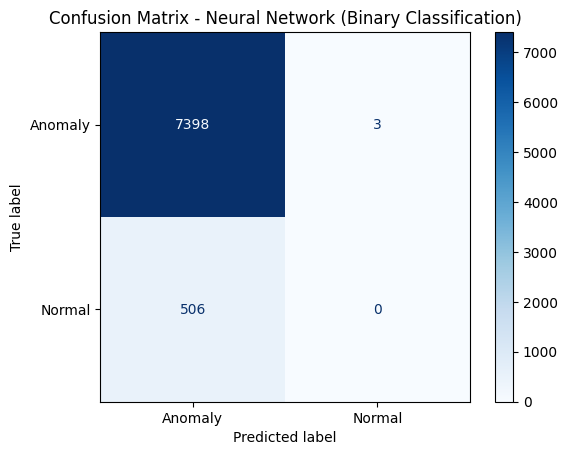

In [ ]:

# Confusion Matrix for Neural Network
cm_nn = confusion_matrix(y_test_binary, y_pred_binary_nn)
disp_nn = ConfusionMatrixDisplay(confusion_matrix=cm_nn, display_labels=label_encoder_binary.classes_)
disp_nn.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - Neural Network (Binary Classification)")
plt.show()

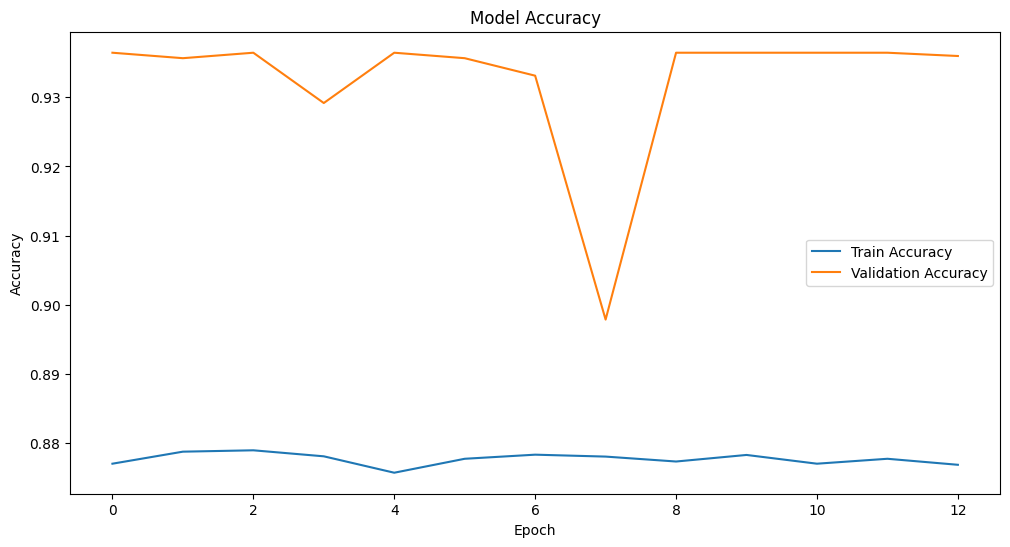

In [ ]:

# Plotting training history
plt.figure(figsize=(12, 6))
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.show()

In [ ]:
# Define the Neural Network Model
model = models.Sequential()
model.add(layers.Dense(64, activation='relu', input_shape=(X_train_binary.shape[1],)))
model.add(layers.Dense(32, activation='relu'))
model.add(layers.Dense(1, activation='sigmoid'))  # Output layer for binary classification

# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
history = model.fit(X_train_binary, y_train_binary, epochs=30, batch_size=32, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(X_test_binary, y_test_binary)
print("Neural Network - Binary Classification")
print("Test Accuracy:", accuracy)

# Predictions
y_pred_binary_nn = (model.predict(X_test_binary) > 0.5).astype("int32")

# Evaluation Metrics
print("Classification Report:\n", classification_report(y_test_binary, y_pred_binary_nn))
print("Confusion Matrix:\n", confusion_matrix(y_test_binary, y_pred_binary_nn))

# Plotting training history
plt.figure(figsize=(12, 6))
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.show()

In [ ]:
# Align multiclass labels after outlier removal
multiclass_labels = multiclass_labels[:len(X)]

# Split data for multiclass classification
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X, multiclass_labels, test_size=0.2, random_state=42
)

# Initialize the Decision Tree Classifier
dt_classifier_multi = DecisionTreeClassifier()

In [ ]:
# Train the model
dt_classifier_multi.fit(X_train_multi, y_train_multi)

# Predictions
y_pred_multi_dt = dt_classifier_multi.predict(X_test_multi)

In [ ]:
# Evaluation Metrics
print("Decision Tree - Multiclass Classification")
print("Accuracy:", accuracy_score(y_test_multi, y_pred_multi_dt))
print("Classification Report:\n", classification_report(y_test_multi, y_pred_multi_dt))
print("Confusion Matrix:\n", confusion_matrix(y_test_multi, y_pred_multi_dt))

Decision Tree - Multiclass Classification
Accuracy: 0.4955103073226255
Classification Report:
               precision    recall  f1-score   support

           0       0.11      0.13      0.11       742
           1       0.06      0.07      0.07       421
           2       0.67      0.70      0.68      5320
           3       0.06      0.04      0.05       506
           4       0.11      0.08      0.10       918

    accuracy                           0.50      7907
   macro avg       0.20      0.20      0.20      7907
weighted avg       0.48      0.50      0.49      7907

Confusion Matrix:
 [[  93   36  513   30   70]
 [  42   30  299   16   34]
 [ 576  329 3698  241  476]
 [  60   33  351   20   42]
 [ 108   54  637   42   77]]


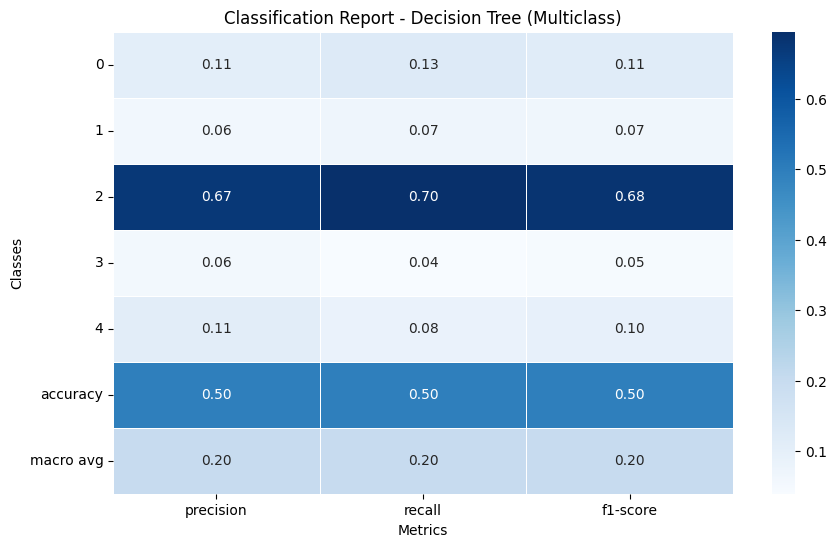

In [ ]:
report_multi_dt = classification_report(y_test_multi, y_pred_multi_dt, output_dict=True)
report_multi_dt_df = pd.DataFrame(report_multi_dt).transpose()
plt.figure(figsize=(10, 6))
sns.heatmap(report_multi_dt_df.iloc[:-1, :-1], annot=True, cmap='Blues', fmt='.2f', linewidths=0.5)
plt.title('Classification Report - Decision Tree (Multiclass)')
plt.xlabel('Metrics')
plt.ylabel('Classes')
plt.show()

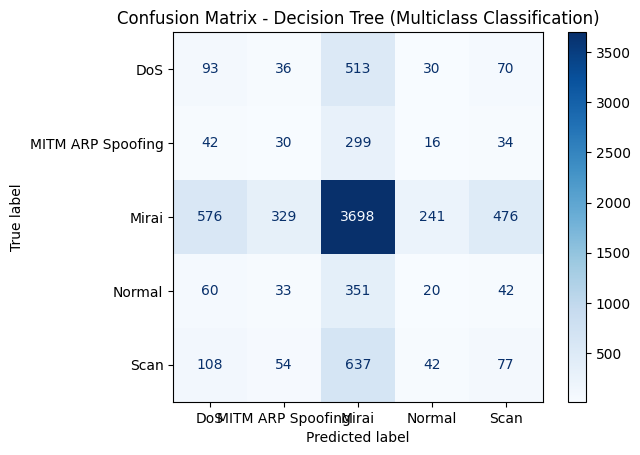

In [ ]:
# Confusion Matrix for Decision Tree (Multiclass)
cm_multi_dt = confusion_matrix(y_test_multi, y_pred_multi_dt)
disp_multi_dt = ConfusionMatrixDisplay(confusion_matrix=cm_multi_dt, display_labels=label_encoder_multi.classes_)
disp_multi_dt.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - Decision Tree (Multiclass Classification)")
plt.show()

In [ ]:
# Tree Visualization
plt.figure(figsize=(20, 10))
tree.plot_tree(dt_classifier_multi, filled=True, feature_names=X.columns, class_names=label_encoder_multi.classes_)
plt.title("Decision Tree Visualization - Multiclass Classification")
plt.show()

KeyboardInterrupt: 

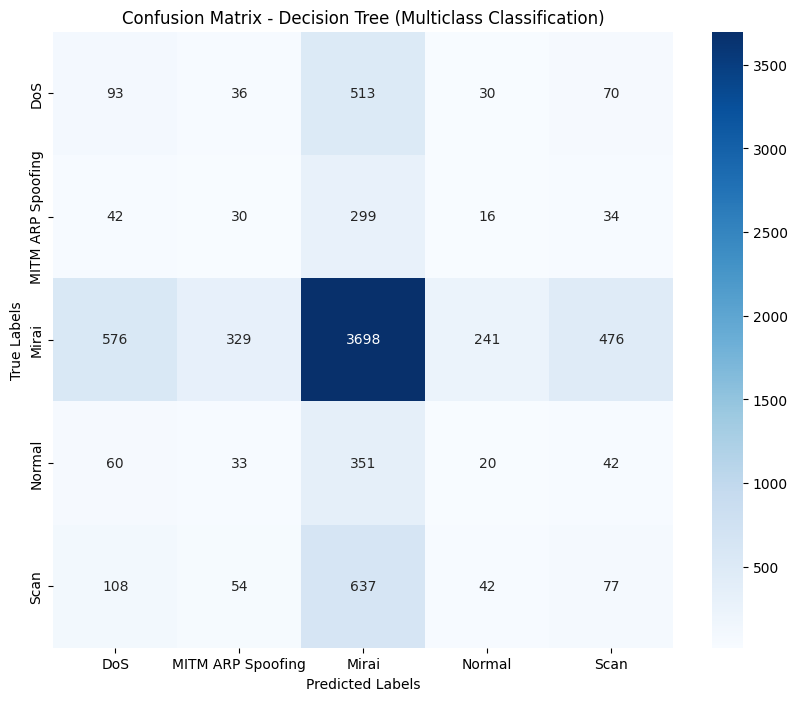

In [ ]:
# Plotting Confusion Matrix
cm_multi = confusion_matrix(y_test_multi, y_pred_multi_dt)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_multi, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder_multi.classes_, yticklabels=label_encoder_multi.classes_)
plt.title("Confusion Matrix - Decision Tree (Multiclass Classification)")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

In [ ]:
# Initialize the Naive Bayes model
nb_classifier = GaussianNB()

# Fit the model to the training data
nb_classifier.fit(X_train_multi, y_train_multi)

# Predict on the test data
y_pred_multi_nb = nb_classifier.predict(X_test_multi)

In [ ]:

# Evaluation Metrics
print("Naive Bayes - Multiclass Classification")
print("Accuracy:", accuracy_score(y_test_multi, y_pred_multi_nb))
print("Classification Report:\n", classification_report(y_test_multi, y_pred_multi_nb))
print("Confusion Matrix:\n", confusion_matrix(y_test_multi, y_pred_multi_nb))

Naive Bayes - Multiclass Classification
Accuracy: 0.6728215505248514
Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00       742
           1       0.00      0.00      0.00       421
           2       0.67      1.00      0.80      5320
           3       0.00      0.00      0.00       506
           4       0.00      0.00      0.00       918

    accuracy                           0.67      7907
   macro avg       0.13      0.20      0.16      7907
weighted avg       0.45      0.67      0.54      7907

Confusion Matrix:
 [[   0    0  742    0    0]
 [   0    0  421    0    0]
 [   0    0 5320    0    0]
 [   0    0  506    0    0]
 [   0    0  918    0    0]]


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


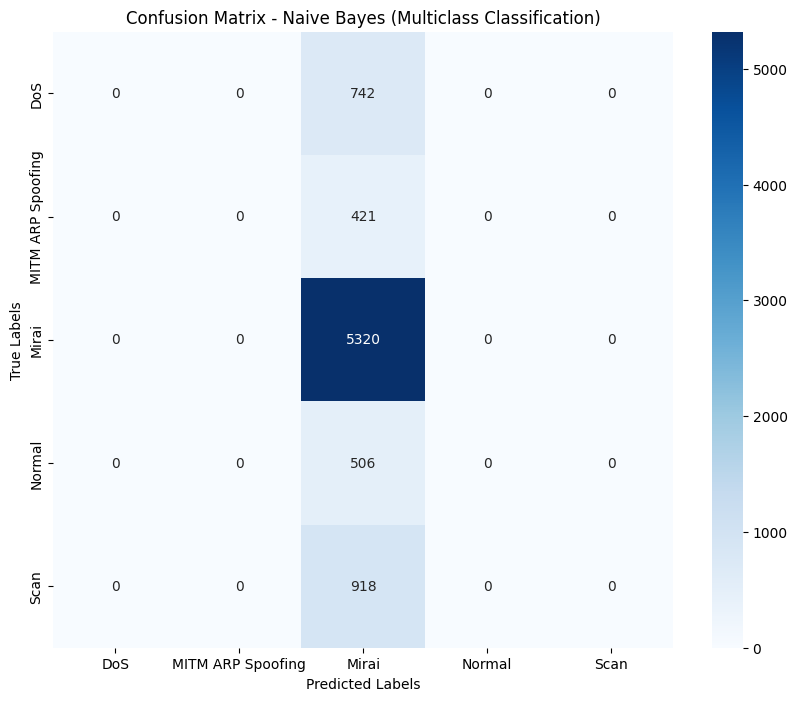

In [ ]:

# Plotting Confusion Matrix
cm_multi_nb = confusion_matrix(y_test_multi, y_pred_multi_nb)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_multi_nb, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder_multi.classes_, yticklabels=label_encoder_multi.classes_)
plt.title("Confusion Matrix - Naive Bayes (Multiclass Classification)")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

## neural network

In [ ]:
# Convert labels to categorical format
num_classes = len(np.unique(y_train_multi))
y_train_multi_cat = pd.get_dummies(y_train_multi).values
y_test_multi_cat = pd.get_dummies(y_test_multi).values

In [ ]:
from keras.models import Sequential
from keras.layers import Dense

In [ ]:

# Build the Neural Network model
model = Sequential()
model.add(Dense(64, activation='relu', input_shape=(X_train_multi.shape[1],)))  # First hidden layer
model.add(Dense(32, activation='relu'))  # Second hidden layer
model.add(Dense(num_classes, activation='softmax'))  # Output layer for multiclass

# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:

# Train the model
history = model.fit(X_train_multi, y_train_multi_cat, epochs=20, batch_size=32, validation_split=0.2)

Epoch 1/20
791/791 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.4503 - loss: 142382.1875 - val_accuracy: 0.6400 - val_loss: 20981.2520
Epoch 2/20
791/791 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4848 - loss: 33474.5039 - val_accuracy: 0.6553 - val_loss: 21822.4980
Epoch 3/20
791/791 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.4648 - loss: 33988.6445 - val_accuracy: 0.1845 - val_loss: 30260.0449
Epoch 4/20
791/791 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4618 - loss: 27258.6777 - val_accuracy: 0.6508 - val_loss: 19019.9355
Epoch 5/20
791/791 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4818 - loss: 24480.4219 - val_accuracy: 0.6675 - val_loss: 22503.2520
Epoch 6/20
791/791 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.4701 - loss: 26791.2422 - val_accuracy: 0.6523 - val_loss: 36758.0664
Epoch 7/20
791/791 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4658 - loss: 21185.7754 - val_accuracy: 0.6515 - val_loss: 28081.4727
Epoch 8/20
791/791 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/

In [ ]:

# Evaluate the model
y_pred_multi_nn = model.predict(X_test_multi)
y_pred_multi_classes = np.argmax(y_pred_multi_nn, axis=1)

248/248 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


## Evaluation metrics

In [ ]:

print("Neural Network - Multiclass Classification")
print("Accuracy:", accuracy_score(y_test_multi, y_pred_multi_classes))
print("Classification Report:\n", classification_report(y_test_multi, y_pred_multi_classes))
print("Confusion Matrix:\n", confusion_matrix(y_test_multi, y_pred_multi_classes))

Neural Network - Multiclass Classification
Accuracy: 0.6726950803085874
Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00       742
           1       0.00      0.00      0.00       421
           2       0.67      1.00      0.80      5320
           3       0.00      0.00      0.00       506
           4       0.50      0.00      0.00       918

    accuracy                           0.67      7907
   macro avg       0.23      0.20      0.16      7907
weighted avg       0.51      0.67      0.54      7907

Confusion Matrix:
 [[   0    0  742    0    0]
 [   0    0  421    0    0]
 [   0    1 5317    0    2]
 [   0    0  506    0    0]
 [   0    0  916    0    2]]


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


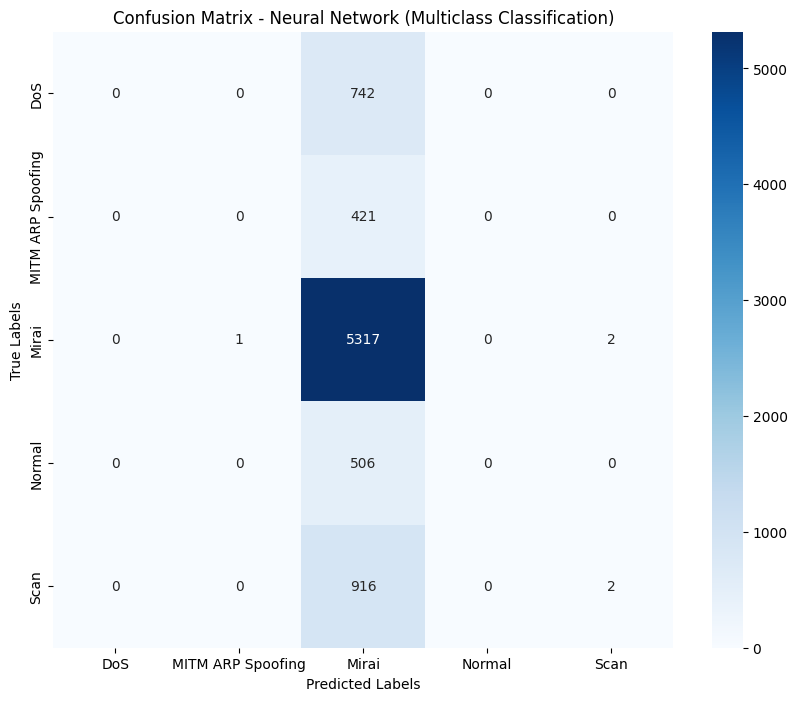

In [ ]:
cm_multi = confusion_matrix(y_test_multi, y_pred_multi_classes)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_multi, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder_multi.classes_, yticklabels=label_encoder_multi.classes_)
plt.title("Confusion Matrix - Neural Network (Multiclass Classification)")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

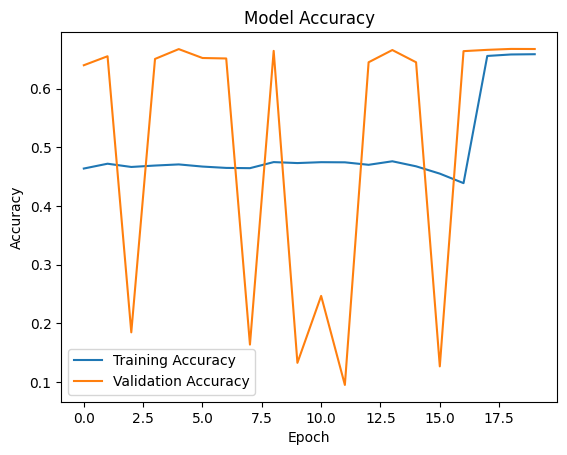

In [ ]:

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.show()